# 06 · 증강 테마 단독 비교 — fold 0 · 250 epoch

한 번 시작하면 **spatial → quality → intensity → none** 순서로 GPU 하나에서 백그라운드 학습·최종 validation을 수행합니다. 각 실험은 무작위 초기화한 새 모델이며 기존 1,000 epoch 가중치에서 이어서 학습하지 않습니다. 브라우저를 닫아도 tmux가 실행을 유지합니다.

| 테마 | 켜는 random augmentation | 끄는 augmentation |
|---|---|---|
| spatial | 회전, mirror, 확대·축소 | 노이즈·블러·저해상도·밝기·대비·gamma·elastic |
| quality | Gaussian noise, blur, 저해상도 흉내 | 회전·mirror·scale·밝기·대비·gamma·elastic |
| intensity | 밝기 배율, contrast | 회전·mirror·scale·노이즈·블러·저해상도·gamma·elastic |
| none (무증강 대조군) | 없음 | 모든 random augmentation |

**공통 조건:** 기존 ACDC 전처리/plans와 환자 단위 fold 0, 3d_fullres, batch 4, 최종 patch `[20,256,224]`, 기본 Dice+CE/SGD/증강 확률·범위, deep supervision, train 250 step·val 50 step/epoch. 전체 학습 길이만 요청에 따라 250으로 줄입니다. 학습률도 총 250 epoch에 맞춰 감소합니다. 이전 실험처럼 compile=false입니다.

패치 위치 샘플링·foreground oversampling·padding·최종 크기로 crop하는 처리는 모든 실험에 유지합니다. 회전/scale을 끈 테마에도 최종 crop을 위한 SpatialTransform이 남지만 해당 변환의 확률은 0입니다. validation transform은 기본값 그대로이며, **최종 전체 볼륨 평가는 모든 테마에서 같은 mirroring TTA**를 사용합니다. 학습 mirror 유무와 평가 방식의 차이를 섞지 않기 위한 공통 조건입니다.

단일 fold·실험당 1회 실행이므로 초기 가중치·샘플링의 무작위 변동이 섞입니다. 세 테마와 무증강 대조군을 기본으로 모두 실행하여, 증강 없는 경우 대비 효과를 비교합니다. 모든 증강을 함께 켠 baseline과의 비교는 포함하지 않습니다.

## 0. 서버 초기화

기존 Python 3.11 venv의 커널을 선택하세요. 새 venv라면 터미널에서 `python -m pip install ipykernel` 후 `python -m ipykernel install --user --name nnunet311 --display-name "Python 3.11 (nnUNet)"`로 등록합니다. 기존 Jupyter 서버를 사용하면 됩니다.

`nnUNet/` 옆에 **전처리까지 완료된 `acdc-data/` 전체**를 복사하세요. 01번 준비가 완료된 데이터가 필요하며 04/05번은 선행 실행할 필요가 없습니다. 원본·전처리·metadata·splits를 재사용하고 데이터 다운로드나 재전처리를 시작하지 않습니다. git, tmux, NVIDIA 드라이버와 CUDA용 PyTorch가 필요합니다.

실행 허용 스위치와 설치 스위치는 기본 False입니다. 이 개발용 컴퓨터에서는 학습하지 않습니다.

설치는 01번 및 기존 성공 기록과 같은 **PyTorch 2.8.0 / CUDA 12.8 wheel**, 대응 torchvision 0.23.0으로 고정합니다. 저장소 의존성 설치 단계에서도 버전을 고정하고, 새 Python 프로세스에서 CUDA를 검사합니다. 서버 드라이버 호환성은 마지막 검사로 확인합니다.


In [1]:
from pathlib import Path
import os, sys, json, subprocess, shlex, shutil
sys.dont_write_bytecode = True
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'nnunetv2').is_dir()), None)
if REPO is None:
    raise RuntimeError('저장소 안에서 노트북을 여세요.')
EXPERIMENT = REPO / 'experiments/acdc'
STORAGE_ROOT = (REPO.parent / 'acdc-data').resolve()
SUITE_ID = 'acdc-aug250-v1'  # 새로운 비교 실험이면 새 이름
GPU = '0'
AUGMENTATION_WORKERS = 4
INCLUDE_NO_AUG_CONTROL = True  # 무증강 대조군도 기본 실행
INSTALL_PACKAGES = False  # 새 Linux 서버 venv에서 처음 한 번 True
START_SUITE = True       # 학습을 시작할 서버에서 True
RESUME = False            # 중단된 동일 실험 재개 시 True
print('Kernel:', sys.executable)
print('Data:', STORAGE_ROOT)
print('Suite:', SUITE_ID)
if STORAGE_ROOT == REPO or REPO in STORAGE_ROOT.parents:
    raise ValueError('acdc-data는 Git 저장소 밖에 두세요.')

Kernel: /root/venvs/nnunet311/bin/python
Data: /root/acdc-data
Suite: acdc-aug250-v1


In [2]:
if INSTALL_PACKAGES:
    if sys.platform != 'linux' or sys.prefix == sys.base_prefix:
        raise RuntimeError('Linux GPU 서버의 venv에서만 설치하세요.')
    if any(name in sys.modules for name in ('torch', 'torchvision', 'numpy', 'nnunetv2')):
        raise RuntimeError('커널을 재시작한 뒤 초기화 셀과 설치 셀부터 실행하세요.')
    # Match notebook 01 and the recorded successful baseline environment.
    # Exact CUDA wheel versions also prevent silently retaining a different CUDA build.
    specs = ['torch==2.8.0+cu128', 'torchvision==0.23.0+cu128']
    from importlib.metadata import version, PackageNotFoundError
    try:
        version('torchaudio')
    except PackageNotFoundError:
        pass
    else:
        specs.append('torchaudio==2.8.0+cu128')
    pip = [sys.executable, '-m', 'pip']
    subprocess.check_call(pip + ['install', '--no-cache-dir', *specs,
                                '--index-url', 'https://download.pytorch.org/whl/cu128'])
    subprocess.check_call(pip + ['install', '--no-cache-dir', *specs,
                                '-e', str(REPO), '-r', str(EXPERIMENT / 'requirements-server.txt')])
    subprocess.check_call(pip + ['check'])
    # Check in a fresh interpreter, avoiding a previously imported torch/CUDA runtime.
    subprocess.check_call([sys.executable, '-c',
        "import torch; print('PyTorch:', torch.__version__, 'CUDA build:', torch.version.cuda); "
        "assert torch.cuda.is_available(), 'CUDA unavailable; inspect nvidia-smi and installed PyTorch build'; "
        "print('GPU:', torch.cuda.get_device_name(0))"])
    print('설치·CUDA 검사 완료. 커널을 재시작하고 INSTALL_PACKAGES=False로 바꾼 뒤 처음부터 실행하세요.')
else:
    print('설치 생략')

설치 생략


In [3]:
sys.path.insert(0, str(EXPERIMENT / 'scripts'))
from run_augmentation_suite import TRAINERS, theme_config, suite_dir, preflight, comparison_rows
from workflow import environment, model_dir, paths, parse_losses, write_json
suite = {
    'suite_id': SUITE_ID, 'storage_root': str(STORAGE_ROOT), 'gpu': GPU,
    'augmentation_workers': AUGMENTATION_WORKERS,
    'themes': ['spatial', 'quality', 'intensity'] + (['none'] if INCLUDE_NO_AUG_CONTROL else []),
    'fold': 0, 'epochs': 250, 'execution_enabled': True,
    'expected_git_commit': subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=REPO, text=True).strip(),
}
SUITE_DIR = suite_dir(suite)
CONFIG_PATH = SUITE_DIR / 'suite.server.json'
SESSION = 'acdc-' + SUITE_ID
for theme in suite['themes']:
    c = theme_config(suite, theme)
    print(f'{theme}: {TRAINERS[theme]}')
    print('  ', model_dir(c) / 'fold_0')
print('총 학습 업데이트:', len(suite['themes']) * 250 * 250)
print('기존 실험 약 70초/epoch 기준 테마당 약 4.9시간 + 최종 평가. 증강에 따라 실제 시간은 달라집니다.')

spatial: nnUNetTrainerACDCSpatial250
   /root/acdc-data/runs/acdc-aug250-v1-spatial/nnUNet_results/Dataset027_ACDC/nnUNetTrainerACDCSpatial250__nnUNetPlans__3d_fullres/fold_0
quality: nnUNetTrainerACDCQuality250
   /root/acdc-data/runs/acdc-aug250-v1-quality/nnUNet_results/Dataset027_ACDC/nnUNetTrainerACDCQuality250__nnUNetPlans__3d_fullres/fold_0
intensity: nnUNetTrainerACDCIntensity250
   /root/acdc-data/runs/acdc-aug250-v1-intensity/nnUNet_results/Dataset027_ACDC/nnUNetTrainerACDCIntensity250__nnUNetPlans__3d_fullres/fold_0
none: nnUNetTrainerACDCNoAug250
   /root/acdc-data/runs/acdc-aug250-v1-none/nnUNet_results/Dataset027_ACDC/nnUNetTrainerACDCNoAug250__nnUNetPlans__3d_fullres/fold_0
총 학습 업데이트: 250000
기존 실험 약 70초/epoch 기준 테마당 약 4.9시간 + 최종 평가. 증강에 따라 실제 시간은 달라집니다.


## 1. 한 번에 백그라운드 큐 시작 / 재개

위에서 `START_SUITE=True`로 바꾼 뒤 아래 셀을 한 번 실행하세요. 시작 전에 CUDA, trainer 발견 여부, 전처리·200개 사례·split·plans를 검사합니다. 네 실험은 서로 다른 run_id와 모델 폴더를 사용하며 기존 baseline을 덮어쓰지 않습니다.

각 테마가 학습과 최종 전체 validation을 끝내면 다음으로 넘어갑니다. 실패하면 큐를 중단해 원인을 로그에 남깁니다. 수정 후 재시작하려면 `RESUME=True`; 완료된 실험은 건너뛰고 중단된 실험은 저장된 checkpoint에서 재개합니다. checkpoint가 하나도 없는 실패 폴더는 자동 삭제하지 않으므로 확인 후 새 SUITE_ID를 사용하세요.

코드·설정·패키지 변경 시 기존 결과와 섞이지 않도록 거부합니다. 의도적으로 설정을 바꾸는 경우 새 SUITE_ID를 쓰세요. 같은 GPU를 사용하는 기존 runner와는 lock으로 중복 실행을 막습니다. 이 노트북의 시작 코드는 실제 GPU 서버에서만 실행됩니다.

In [4]:
if not START_SUITE:
    print('실행 생략. GPU 서버에서 START_SUITE=True로 변경하세요.')
else:
    if sys.platform != 'linux':
        raise RuntimeError('Linux GPU 서버에서만 시작할 수 있습니다.')
    for tool in ('git', 'tmux', 'nvidia-smi', 'nnUNetv2_train'):
        search_path = str(Path(sys.executable).parent) + os.pathsep + os.environ.get('PATH', '')
        if shutil.which(tool, path=search_path) is None:
            raise RuntimeError(f'먼저 설치하세요: {tool}')
    if subprocess.run(['tmux', 'has-session', '-t', SESSION], capture_output=True).returncode == 0:
        print('이미 실행 중:', SESSION)
    else:
        preflight(suite)
        SUITE_DIR.mkdir(parents=True, exist_ok=True)
        if CONFIG_PATH.exists() and json.loads(CONFIG_PATH.read_text()) != suite:
            raise ValueError('기존 suite 설정과 다릅니다. 새 SUITE_ID를 사용하세요.')
        write_json(CONFIG_PATH, suite)
        # Validate exact recipe schema before creating the tmux session.
        from run_augmentation_suite import read_suite
        read_suite(CONFIG_PATH)
        command = [sys.executable, '-u', str(EXPERIMENT / 'scripts/run_augmentation_suite.py'),
                   '--config', str(CONFIG_PATH)]
        if RESUME:
            command.append('--resume')
        runner_log = SUITE_DIR / 'runner.log'
        shell_command = shlex.join(command) + ' >> ' + shlex.quote(str(runner_log)) + ' 2>&1'
        subprocess.run(['tmux', 'new-session', '-d', '-s', SESSION, shell_command],
                       env=environment(theme_config(suite, suite['themes'][0])), check=True)
        print('Started:', SESSION)
        print('Runner log:', runner_log)
        print('시작 직후 아래 상태 셀에서 프로세스가 정상적으로 유지되는지 확인하세요.')

NVIDIA GeForce RTX 3090 23.68 GiB
Free disk: 89.07 GiB


/root/venvs/nnunet311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Started: acdc-acdc-aug250-v1
Runner log: /root/acdc-data/augmentation_suites/acdc-aug250-v1/runner.log
시작 직후 아래 상태 셀에서 프로세스가 정상적으로 유지되는지 확인하세요.


## 2. 상태와 최근 로그

이 셀은 다시 실행해도 학습을 새로 시작하지 않습니다. `running` 상태인데 tmux 세션이 없으면 비정상 종료일 수 있으므로 로그를 확인하세요. 실제 학습 상세 로그는 각 run의 `logs/fold_0.console.log`에 있습니다.

In [5]:
from collections import deque
status_path = SUITE_DIR / 'status.json'
status = json.loads(status_path.read_text()) if status_path.exists() else {}
print('Suite status:', status.get('status', 'not_started'))
print('Active:', status.get('active_theme'))
print('Themes:', status.get('themes', {}))
if shutil.which('tmux'):
    print('tmux alive:', subprocess.run(['tmux', 'has-session', '-t', SESSION],
                                        capture_output=True).returncode == 0)
for theme in suite['themes']:
    c = theme_config(suite, theme)
    folder = model_dir(c) / 'fold_0'
    losses = parse_losses(folder)
    print(theme, f'last logged epoch: {losses[-1]["epoch"] + 1 if losses else 0}/250')
active = status.get('active_theme')
log = (paths(theme_config(suite, active))['run'] / 'logs/fold_0.console.log'
       if active in suite['themes'] else SUITE_DIR / 'runner.log')
if log.exists():
    with log.open(errors='replace') as f:
        print(''.join(deque(f, maxlen=25)))
if status.get('error'):
    print('ERROR:', status['error'])

Suite status: running
Active: spatial
Themes: {'spatial': 'running'}
tmux alive: True
spatial last logged epoch: 0/250
quality last logged epoch: 0/250
intensity last logged epoch: 0/250
none last logged epoch: 0/250
############################
INFO: You are using the old nnU-Net default plans. We have updated our recommendations. Please consider using those instead! Read more here: https://github.com/MIC-DKFZ/nnUNet/blob/master/documentation/resenc_presets.md
############################

Using device: cuda:0

#######################################################################
Please cite the following paper when using nnU-Net:
Isensee, F., Jaeger, P. F., Kohl, S. A., Petersen, J., & Maier-Hein, K. H. (2021). nnU-Net: a self-configuring method for deep learning-based biomedical image segmentation. Nature methods, 18(2), 203-211.
#######################################################################


This is the configuration used by this training:
Configuration name: 3d_fullres

## 3. Train / validation loss 함께 보기

각 테마의 학습 곡선을 같은 축 범위로 비교합니다. epoch는 화면에서 1부터 표시합니다. 노트북 셀을 다시 실행해 갱신할 수 있으며, 이 셀을 중단해도 백그라운드 학습은 계속됩니다.

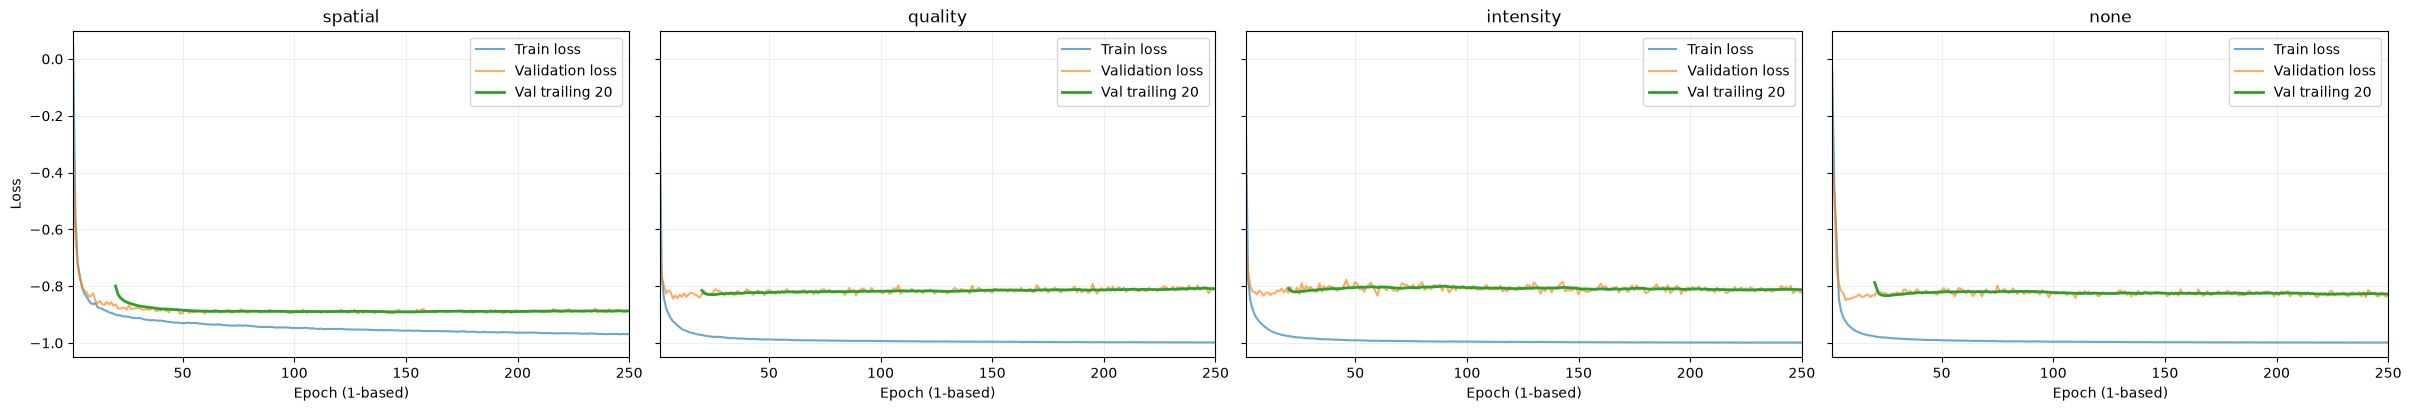

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
fig, axes = plt.subplots(1, len(suite['themes']), figsize=(6 * len(suite['themes']), 4),
                         sharex=True, sharey=True, squeeze=False, constrained_layout=True)
for ax, theme in zip(axes[0], suite['themes']):
    frame = pd.DataFrame(parse_losses(model_dir(theme_config(suite, theme)) / 'fold_0'))
    if not frame.empty:
        x = frame.epoch + 1
        ax.plot(x, frame.train_loss, alpha=.65, label='Train loss')
        ax.plot(x, frame.val_loss, alpha=.65, label='Validation loss')
        ax.plot(x, frame.val_loss.rolling(20, min_periods=20).mean(), lw=2, label='Val trailing 20')
        ax.legend()
    ax.set(title=theme, xlabel='Epoch (1-based)', xlim=(1, 250))
    ax.grid(alpha=.2)
axes[0][0].set_ylabel('Loss')
plt.show()
plt.close(fig)

## 4. 완료된 실험의 전체 볼륨 평가 비교

큐가 테마 하나를 완료할 때마다 `comparison.csv`와 `comparison.json`을 자동 갱신합니다. 아래 표는 각 실험의 `checkpoint_final` 전체 validation 40개 결과를 읽습니다. **mIoU는 여기서는 실제 전체 볼륨 평가 지표**이며, epoch 로그의 pseudo-mIoU와 다릅니다. 기본 nnU-Net summary의 클래스별 사례 평균 및 foreground 클래스 평균을 사용합니다. NSD는 이 큐에서 추가 계산하지 않습니다.

학습 mirror를 끈 테마도 최종 평가는 공통 default mirroring TTA를 사용합니다. 효과의 통계적 확증에는 반복 seed/fold 실험이 필요합니다. 기존 1,000 epoch all-augmentation baseline과는 학습 예산이 달라 직접적인 증강 효과로만 해석할 수 없습니다.

,theme,run_id,fold,epochs,checkpoint,status,dice_percent,miou_percent,dice_RV_percent,iou_RV_percent,dice_MLV_percent,iou_MLV_percent,dice_LVC_percent,iou_LVC_percent
0,spatial,acdc-aug250-v1-spatial,0,250,final,completed,91.868632,85.398830,90.608263,83.425321,90.160295,82.252606,94.837340,90.518563
1,quality,acdc-aug250-v1-quality,0,250,final,completed,72.493647,61.563715,50.106794,37.349574,77.837563,64.792539,89.536585,82.549033
2,intensity,acdc-aug250-v1-intensity,0,250,final,completed,71.954250,61.775231,43.721277,31.106484,81.601553,70.255974,90.539921,83.963235
3,none,acdc-aug250-v1-none,0,250,final,completed,71.107335,60.184193,44.110385,31.117968,81.258870,69.427691,87.952750,80.006920


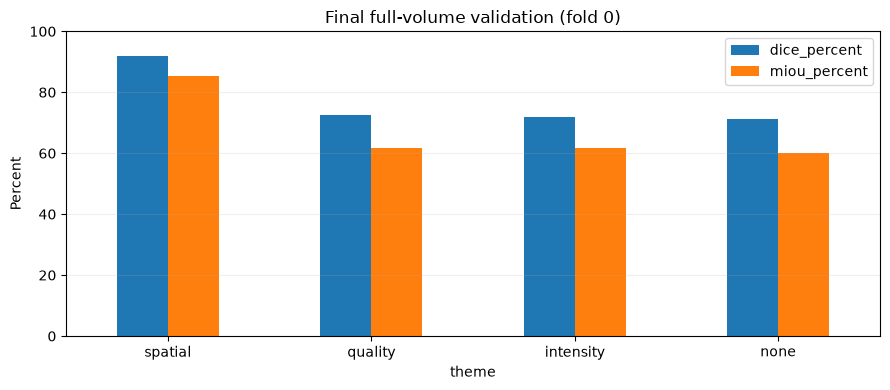

자동 저장 위치: /root/acdc-data/augmentation_suites/acdc-aug250-v1/comparison.csv


In [17]:
comparison = pd.DataFrame(comparison_rows(suite))
display(comparison)
complete = comparison[comparison.status == 'completed']
if not complete.empty:
    ax = complete.set_index('theme')[['dice_percent', 'miou_percent']].plot.bar(
        figsize=(9, 4), ylim=(0, 100), rot=0, ylabel='Percent', title='Final full-volume validation (fold 0)')
    ax.grid(axis='y', alpha=.2)
    plt.tight_layout()
    plt.show()
    plt.close(ax.figure)
print('자동 저장 위치:', SUITE_DIR / 'comparison.csv')

## 5. 필요할 때만 중단

아래 셀은 기본적으로 아무것도 하지 않습니다. `STOP_SUITE=True`로 바꾸면 tmux 세션에 Ctrl+C를 보내 현재 학습과 큐를 중단합니다. 체크포인트 저장·자식 프로세스 종료에 시간이 걸릴 수 있으므로 상태와 GPU를 확인한 뒤 재개하세요. 현재 테마 뒤의 실험은 시작하지 않습니다. 서버 자체가 종료되면 tmux도 유지되지 않습니다.

터미널에서 확인하려면 `tmux attach -t <위 SESSION 값>`을 사용하세요. 화면에서 빠져나와 학습을 유지하려면 Ctrl+B 다음 D입니다.

In [ ]:
STOP_SUITE = False
if STOP_SUITE:
    if sys.platform != 'linux' or not shutil.which('tmux'):
        raise RuntimeError('서버의 tmux 환경에서 실행하세요.')
    subprocess.run(['tmux', 'send-keys', '-t', SESSION, 'C-c'], check=True)
    print('중단 요청 전송. 상태·로그·GPU 프로세스를 확인하세요.')
else:
    print('중단 요청 없음')

## 6. 기존 1,000 epoch baseline + 모든 테마의 best 비교

모든 실험의 학습과 final validation이 완료된 뒤, **GPU 서버에서 `RUN_BEST_EVALUATION=True`**로 바꾸고 실행하세요. 학습은 다시 하지 않으며, 각 `checkpoint_best`로 같은 fold 0 validation 40개를 순서대로 추론합니다. 이 셀은 **포그라운드 실행**이므로 커널을 유지하세요. 중단 후 같은 설정으로 재실행하면 유효한 예측은 재사용합니다. 학습 큐가 GPU를 사용 중이면 실행을 거부합니다.

- `best`는 학습 중 **EMA pseudo-Dice**로 선택된 체크포인트입니다. 표의 epoch는 체크포인트에 기록된 완료 epoch 수(1부터)입니다.
- 실제 3D 전체 볼륨의 RV·MLV·LVC별 Dice/IoU를 사례 평균한 뒤, 세 클래스 평균 Dice·mIoU를 계산합니다. 배경은 제외하며 두 마스크 모두 없는 클래스는 해당 사례 평균에서 제외합니다.
- 모든 모델에 동일한 mirroring TTA(세 축), sliding-window step 0.5, Gaussian weighting을 적용합니다. 기존 final 예측·평가는 덮어쓰지 않습니다.
- baseline은 1,000 epoch, 테마들은 250 epoch 학습이므로 **이 비교만으로 증강의 효과를 분리할 수 없습니다**. 동일 validation으로 best 선택과 평가를 하므로 독립 test 성능도 아닙니다.

결과는 `acdc-data/augmentation_suites/<SUITE_ID>/<BEST_OUTPUT_ID>/` 아래 예측 마스크, 사례별 CSV, 요약 CSV/JSON, 비교 그래프로 저장합니다. 확률 배열은 저장하지 않습니다. 이미 평가했다면 `False`로 두어 저장된 결과만 볼 수 있습니다. 체크포인트·코드·환경을 바꿨다면 새 `BEST_OUTPUT_ID`를 지정하세요.


=== baseline_1000: checkpoint_best, same fold 0 validation ===
There are 40 cases in the source folder
I am process 0 out of 1 (max process ID is 0, we start counting with 0!)
There are 40 cases that I would like to predict
NiftiImageIO (0x9a2ab10): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/imagesTr/patient005_frame01_0000.nii.gz has unexpected scales in sform

NiftiImageIO (0x9a2ab10): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/imagesTr/patient005_frame01_0000.nii.gz has unexpected scales in sform

perform_everything_on_device: True

100%|██████████| 2/2 [00:00<00:00,  3.96it/s]
NiftiImageIO (0x1990a8e0): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/imagesTr/patient005_frame13_0000.nii.gz has unexpected scales in sform

NiftiImageIO (0x1990a8e0): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/imagesTr/patient005_frame13_0000.nii.gz has unexpected scales in sform

perform_everything_on_device: True

100%|██████████| 2/2 [00:00<00:00,  7.78it/s]
NiftiImageIO (0x1990a8e0): /root/acdc-data/nnU

,experiment,training_budget,checkpoint_completed_epochs,validation_cases,dice_percent,miou_percent,dice_delta_pp,miou_delta_pp,dice_RV_percent,dice_MLV_percent,dice_LVC_percent
0,baseline_1000,1000,181,40,92.223,85.939,0.000,0.000,90.957,90.729,94.983
1,spatial,250,145,40,91.968,85.550,-0.255,-0.390,90.801,90.208,94.896
2,quality,250,85,40,75.594,64.408,-16.629,-21.531,58.934,78.742,89.104
3,intensity,250,219,40,72.789,62.468,-19.434,-23.472,46.197,81.615,90.555
4,none,250,223,40,71.502,60.519,-20.721,-25.421,45.221,81.152,88.132


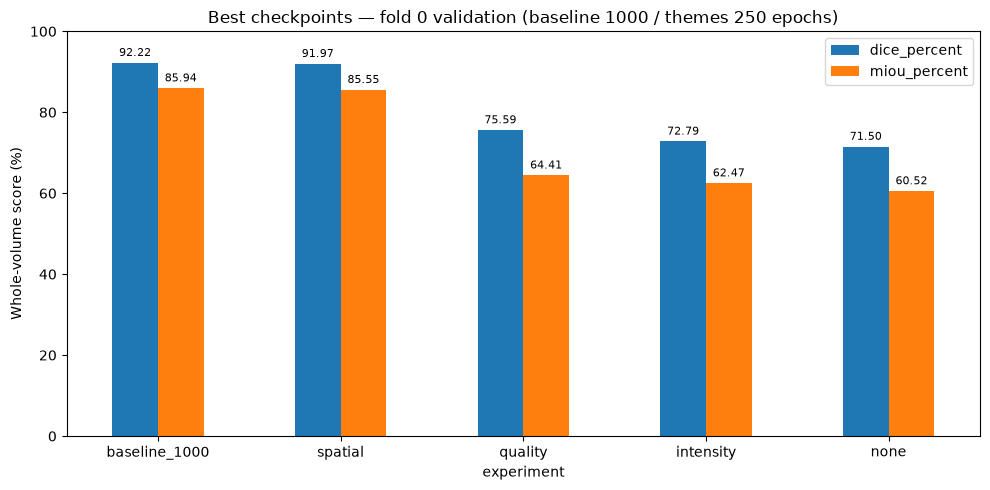

Δpp = baseline 대비 퍼센트포인트 차이. 결과: /root/acdc-data/augmentation_suites/acdc-aug250-v1/best-comparison-v1


In [20]:
RUN_BEST_EVALUATION = True
BASELINE_RUN_ID = 'acdc-baseline-v1'
BEST_OUTPUT_ID = 'best-comparison-v1'

import re
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

if not re.fullmatch(r'[A-Za-z0-9_-]+', BEST_OUTPUT_ID):
    raise ValueError('BEST_OUTPUT_ID에는 영문, 숫자, _, -만 사용하세요.')
best_output = SUITE_DIR / BEST_OUTPUT_ID
if RUN_BEST_EVALUATION:
    if not CONFIG_PATH.is_file():
        raise FileNotFoundError(f'실험 suite 설정이 없습니다: {CONFIG_PATH}')
    command = [sys.executable, '-u', str(EXPERIMENT / 'analysis' / 'compare_best.py'),
               '--config', str(CONFIG_PATH), '--baseline-run', BASELINE_RUN_ID,
               '--output-id', BEST_OUTPUT_ID]
    process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, bufsize=1)
    try:
        for line in process.stdout:
            print(line, end='', flush=True)
        if process.wait() != 0:
            raise RuntimeError('best 평가가 실패했습니다. 위 로그를 확인하세요.')
    finally:
        if process.poll() is None:
            process.terminate()
            try:
                process.wait(timeout=15)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
        process.stdout.close()

result_file = best_output / 'comparison.json'
if not result_file.is_file():
    print('저장된 best 평가 없음. 모든 학습 완료 후 GPU 서버에서 RUN_BEST_EVALUATION=True로 실행하세요.')
else:
    result = json.loads(result_file.read_text())
    best_comparison = pd.DataFrame(result['results'])
    expected = {'baseline_1000', *suite['themes']}
    if not result['complete'] or set(best_comparison['experiment']) != expected:
        print('일부 모델만 평가된 결과입니다. 전체 비교를 위해 평가를 재실행하세요.')
    if best_comparison.loc[best_comparison.experiment == 'baseline_1000', 'run_id'].tolist() != [BASELINE_RUN_ID]:
        raise ValueError('저장된 baseline과 BASELINE_RUN_ID가 다릅니다. 새 BEST_OUTPUT_ID로 평가하세요.')
    baseline = best_comparison.loc[best_comparison.experiment == 'baseline_1000'].iloc[0]
    for metric in ('dice', 'miou'):
        best_comparison[f'{metric}_delta_pp'] = best_comparison[f'{metric}_percent'] - baseline[f'{metric}_percent']
    columns = ['experiment', 'training_budget', 'checkpoint_completed_epochs', 'validation_cases',
               'dice_percent', 'miou_percent', 'dice_delta_pp', 'miou_delta_pp',
               'dice_RV_percent', 'dice_MLV_percent', 'dice_LVC_percent']
    display(best_comparison[columns].round(3))
    ax = best_comparison.set_index('experiment')[['dice_percent', 'miou_percent']].plot.bar(
        figsize=(10, 5), ylim=(0, 100), rot=0, ylabel='Whole-volume score (%)',
        title='Best checkpoints — fold 0 validation (baseline 1000 / themes 250 epochs)')
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', fontsize=8, padding=3)
    ax.figure.tight_layout()
    ax.figure.savefig(best_output / 'comparison.png', dpi=160)
    plt.show()
    print('Δpp = baseline 대비 퍼센트포인트 차이. 결과:', best_output)
